# Question 4 · Discovering topics with LDA


In [ ]:
from pathlib import Path, PurePosixPath
import re, zipfile, html, unicodedata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer, ENGLISH_STOP_WORDS
from sklearn.decomposition import NMF
from sklearn.preprocessing import normalize

path = next(p for p in (Path('data/research_corpus.zip'), Path('../data/research_corpus.zip'), Path('research_corpus.zip'), Path('upload/research_corpus.zip')) if p.exists())
with zipfile.ZipFile(path) as archive:
    names = sorted((n for n in archive.namelist() if n.lower().endswith('.txt')),
                   key=lambda n: int(re.search(r'(\d+)\.txt$', n).group(1)))
    articles = pd.DataFrame([{'article': i, 'filename': PurePosixPath(n).name,
                              'content': archive.read(n).decode('utf-8-sig')}
                             for i, n in enumerate(names, 1)]).set_index('article')
print(articles.assign(characters=articles.content.str.len(),
                      opening=articles.content.str.replace(r'\s+', ' ', regex=True).str[:65])
      [['filename', 'characters', 'opening']].to_string())

               filename  characters                                                            opening
article                                                                                               
1        research_1.txt       38598  The purposes of this article are to position mixed methods resear
2        research_2.txt       16279  Now I see it, now I don’t: researcher’s position and reflexivity 
3        research_3.txt       26521  DEVELOPMENTAL RESEARCH: STUDIES OF INSTRUCTIONAL DESIGN AND DEVEL
4        research_4.txt       39072  Abstract Cronbach’s alpha is a statistic commonly quoted by autho
5        research_5.txt       27142  Denzin’s Paradigm Shift: Revisiting Triangulation in Qualitative 


In [ ]:
front_matter = {2: 'Abstract', 3: '41.1 INTRODUCTION', 5: 'One approach to promote'}
layout = re.compile(r'^(?:\d+|abstract|article|Berger \d+|\d+ Qualitative Research.*|'
                    r'Fusch, Fusch, & Ness, 2018|Journal of Social Change \d+|'
                    r'\d+ EDUCATIONAL RESEARCHER|OCTOBER 2004 \d+|\d+ • RICHEY.*|'
                    r'Mixed Methods Research:|A Research Paradigm Whose Time Has Come|'
                    r'by R\. Burke Johnson.*|41\.\d+(?:\.\d+)* [A-Z][^.]{0,65})$', re.I)
def denoise(article, raw):
    text = unicodedata.normalize('NFKC', html.unescape(raw)).replace('\r\n', '\n')
    text = re.sub(r'[\x00-\x09\x0b-\x1f\xad]', ' ', text)
    if article in front_matter:
        text = text[text.index(front_matter[article]):]
    text = re.sub(r'(?m)^Corresponding author:.*?^Article\s*$', '', text, flags=re.S)
    text = re.sub(r'(?m)^Keywords\s*\n[^\n]+|^Keywords:.*?\nIntroduction\b', '', text, flags=re.S)
    text = '\n'.join(l for l in text.splitlines() if not layout.fullmatch(l.strip()))
    text = re.sub(r'(?<=\w)-\n(?=[a-z])', '', text)
    text = re.sub(r'https?://\S+|[\w.+-]+@[\w.-]+\.[a-z]+', ' ', text)
    text = re.sub(r'Educational Researcher, Vol\. 33, No\. 7, pp\. 14–26', ' ', text)
    text = ' '.join(text.split())
    cut = text.find(text[:100], 100)
    doubled = cut > 0 and text[:cut].strip() == text[cut:].strip()
    if doubled:
        text = text[:cut].strip()
    text = re.sub(r'\([^()]*(?:19|20)\d{2}[^()]*\)', '', text)
    text = re.sub(r'(?<=[.!?])\d{1,2}(?=\s+[A-Z])', '', text)
    text = re.sub(r'(?<=[a-z][.!?])(?=[A-Z])', ' ', text)
    text = re.sub(r'\s+([,.;:])', r'\1', ' '.join(text.split()))
    return text, doubled

def split_sentences(text):
    protected = re.sub(r'\b(?:e\.g\.|i\.e\.|et al\.|Fig\.|Dr\.)',
                       lambda m: m[0].replace('.', '∯'), text, flags=re.I)
    return [s.replace('∯', '.').strip() for s in re.split(r'(?<=[.!?])\s+(?=[“"‘(A-Z])', protected) if s]

cleaned = [denoise(i, row.content) for i, row in articles.iterrows()]
articles['clean'] = [x[0] for x in cleaned]
articles['sentences'] = articles.clean.map(split_sentences)
audit = pd.DataFrame({'raw_words': articles.content.str.split().str.len(),
                      'clean_words': articles.clean.str.split().str.len(),
                      'sentences': articles.sentences.str.len(),
                      'repeated_copy_removed': [x[1] for x in cleaned]})
assert articles.clean.str.len().gt(0).all()
print(audit.to_string())
# Filter common words only in the feature matrix. Retain negation.
stop = sorted(set(ENGLISH_STOP_WORDS) - {'no', 'not', 'never', 'without'})
def vectorizer(**kwargs):
    return TfidfVectorizer(stop_words=stop, ngram_range=(1, 2), sublinear_tf=True, **kwargs)

         raw_words  clean_words  sentences  repeated_copy_removed
article                                                          
1             5602         2597         75                   True
2             2416         2181         58                  False
3             3828         3610        159                  False
4             5922         5764        177                  False
5             4027         3601        159                  False


## 4.1 · Topic words and distributions


In [ ]:
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.decomposition import LatentDirichletAllocation
from scipy.spatial.distance import pdist, squareform, jensenshannon
import json
root = next(p for p in (Path.cwd(), Path.cwd().parent) if (p/'data/research_corpus.zip').exists())
outdir = root/'results'
outdir.mkdir(exist_ok=True)
passages = pd.DataFrame([{'article': doc, 'text': ' '.join(ss[i:i+6])}
                         for doc, ss in articles.sentences.items() for i in range(0,len(ss),6)])
generic = {'research','article','study','studies','paper','example','authors','et','al','used','using'}
cv = CountVectorizer(stop_words=sorted(set(stop) | generic), min_df=2,
                     token_pattern=r'(?u)\b[a-zA-Z][a-zA-Z]+\b')
counts = cv.fit_transform(passages.text)
lengths = np.asarray(counts.sum(axis=1)).ravel()
keep = lengths > 0
counts, lengths = counts[keep], lengths[keep]
ids = passages.article.to_numpy()[keep]
terms = cv.get_feature_names_out()
lda = LatentDirichletAllocation(n_components=5, learning_method='batch', max_iter=100,
                                doc_topic_prior=0.1, random_state=42)
theta = lda.fit_transform(counts)
phi = lda.components_ / lda.components_.sum(axis=1, keepdims=True)
# Keep original component indices stable in tables, plots and map.
mass = pd.DataFrame(theta * lengths[:,None], index=ids).groupby(level=0).sum()
shares = mass.div(mass.sum(axis=1), axis=0)
prevalence = mass.sum(axis=0).to_numpy() / lengths.sum()
assert np.allclose(shares.sum(axis=1),1) and np.isclose(prevalence.sum(),1)
print(f'{counts.shape[0]} nonempty passages, {len(terms)} modelled terms, {lengths.sum()} retained tokens.')
for i, weights in enumerate(phi):
    print(f'T{i+1} ({prevalence[i]:.1%}):', ', '.join(terms[weights.argsort()[::-1][:10]]))
shares.columns = [f'T{i+1}' for i in range(5)]
print((100*shares).round(1).to_string())

107 nonempty passages, 1157 modelled terms, 7234 retained tokens.
T1 (32.7%): alpha, cronbach, instrument, science, reliability, values, not, items, education, scales
T2 (21.0%): development, researcher, process, reflexivity, knowledge, developmental, evaluation, type, experience, design
T3 (20.3%): design, methods, mixed, development, instructional, quantitative, qualitative, process, researchers, not
T4 (15.4%): triangulation, data, denzin, validity, not, multiple, researcher, methodological, methods, qualitative
T5 (10.6%): qualitative, data, social, researchers, triangulation, bias, change, multiple, researcher, personal
     T1    T2    T3    T4    T5
1   2.5   3.0  46.7  21.2  26.6
2   0.9  91.9   1.0   2.1   4.2
3   2.7  52.9  39.2   3.7   1.6
4  92.6   0.1   1.2   3.8   2.3
5   0.2   1.5  24.7  48.3  25.3


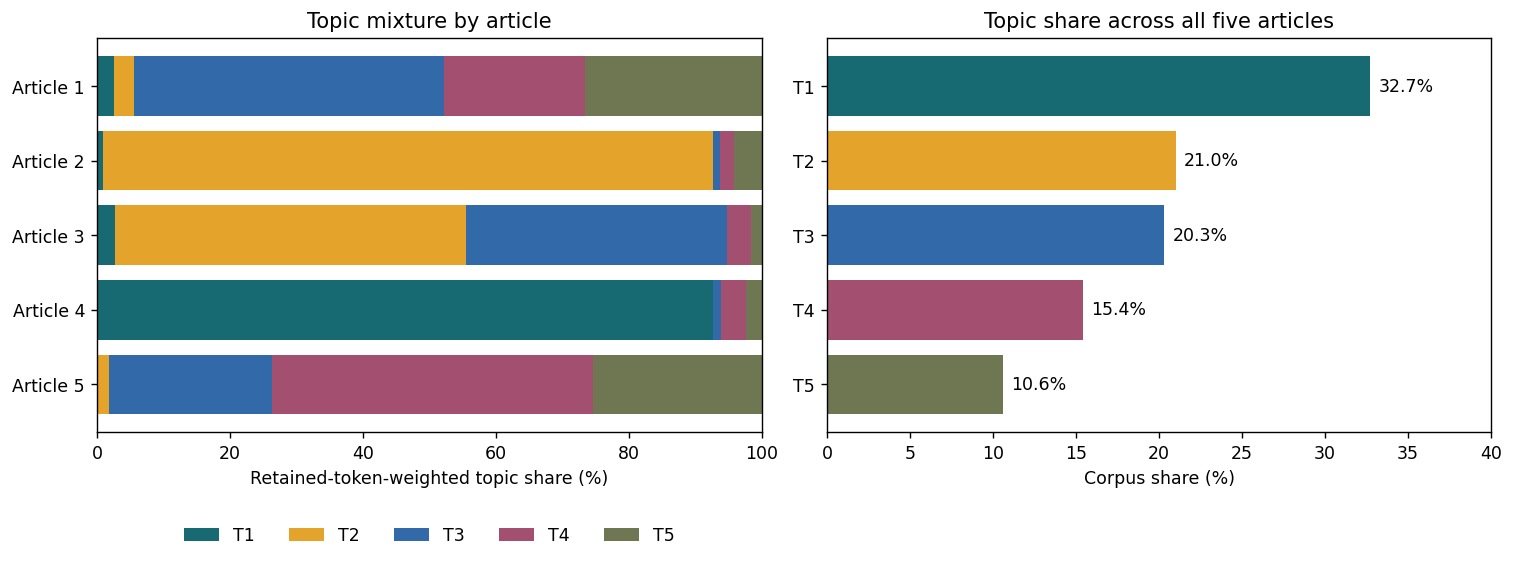

In [ ]:
labels = ['Reliability of measures', 'Development and reflexivity', 'Mixed methods and design',
          'Triangulation and validity', 'Qualitative data and bias']
colors = ['#186a72','#e4a32b','#3169a9','#a34f70','#6f7752']
fig, (left,right) = plt.subplots(1,2, figsize=(12,4.4), layout='constrained')
offset = np.zeros(len(shares))
for i, label in enumerate(labels):
    values = 100*shares.iloc[:, i].to_numpy()
    left.barh([f'Article {j}' for j in shares.index], values, left=offset, color=colors[i], label=f'T{i+1}')
    offset += values
left.invert_yaxis()
left.set(xlim=(0,100), xlabel='Retained-token-weighted topic share (%)', title='Topic mixture by article')
left.legend(ncol=5, loc='upper center', bbox_to_anchor=(0.5,-0.20), frameon=False)
right.barh([f'T{i+1}' for i in range(5)], 100*prevalence, color=colors)
right.invert_yaxis()
right.set(title='Topic share across all five articles', xlabel='Corpus share (%)',xlim=(0,40))
for i,v in enumerate(prevalence):right.text(v*100+0.5,i,f'{v:.1%}',va='center')
fig.savefig(outdir/'lda-distribution.png',dpi=145,bbox_inches='tight')
plt.show()

## 4.2 · Interactive intertopic distance map


In [ ]:
D = squareform(pdist(phi, metric=jensenshannon))
J = np.eye(5) - np.ones((5,5))/5
eigenvalues, axes = np.linalg.eigh(-0.5*J @ (D**2) @ J)
idx = eigenvalues.argsort()[::-1][:2]
xy = axes[:,idx] * np.sqrt(np.maximum(eigenvalues[idx],0))
marginal = prevalence @ phi
posterior = (prevalence[:,None]*phi)/marginal
saliency = marginal * np.sum(posterior * np.log(posterior / prevalence[:,None]),axis=0)
payload = dict(labels=labels, terms=terms.tolist(), xy=xy.tolist(), prevalence=prevalence.tolist(),
               phi=phi.tolist(), marginal=marginal.tolist(), saliency=saliency.tolist(), colors=colors)
print('Two-dimensional share of positive eigenvalue mass:',
      round(eigenvalues[idx].sum()/eigenvalues[eigenvalues>0].sum(),3))

Two-dimensional share of positive eigenvalue mass: 0.613


In [ ]:
template = r'''<!doctype html><html lang="en"><meta charset="utf-8"><meta name="viewport" content="width=device-width,initial-scale=1"><title>Researchly · Intertopic distance map</title><style>
*{box-sizing:border-box}body{margin:0;background:#f5f6f3;color:#173339;font:16px/1.45 system-ui,sans-serif}main{max-width:1100px;margin:35px auto;padding:0 22px}h1{font:600 clamp(30px,4vw,46px)/1.05 Georgia,serif;margin:0}h2{font-size:20px;margin:0 0 8px}section{background:white;border:1px solid #d5dedb;border-radius:12px;padding:20px}article{display:grid;grid-template-columns:1fr 1fr;gap:16px}svg{width:100%;height:auto}circle{cursor:pointer}g[role=button]:focus circle,g[aria-pressed=true] circle{stroke:#142d34;stroke-width:4}g text{fill:white;font:bold 15px system-ui;pointer-events:none}button{background:white;border:1px solid #829794;border-radius:6px;padding:7px 12px;cursor:pointer}input{vertical-align:middle}#bars{list-style:none;padding:0}.bar{background:#31727b;height:8px;border-radius:4px}.row{display:flex;justify-content:space-between;margin-top:5px;font-size:14px}small{color:#4c6363}@media(max-width:700px){article{grid-template-columns:1fr}}
</style><main><h1>Intertopic distance map</h1><p>Five topics across five research articles. Select a circle to explore its vocabulary.</p><article><section><h2>Topic distances</h2><small>Circle area shows corpus share. Nearby centres indicate similar word distributions in this projection.</small><svg viewBox="0 0 450 390" aria-label="Interactive topic map"></svg><div id="legend"></div><button id="reset">Show corpus overview</button></section><section><h2 id="heading"></h2><label for="lambda">Term relevance λ </label><input type="range" id="lambda" min="0" max="1" step=".05" value=".6"><output id="value">0.60</output><p><small id="caption"></small></p><ol id="bars"></ol></section></article></main>
<script>
const m=__MODEL__,svg=document.querySelector('svg'),ns='http://www.w3.org/2000/svg';
let selected=-1;
function node(tag,attrs,parent){const el=document.createElementNS(ns,tag);Object.entries(attrs).forEach(([key,val])=>el.setAttribute(key,val));parent.append(el);return el}
const scale=Math.min(155/Math.max(...m.xy.map(a=>Math.abs(a[0]))),138/Math.max(...m.xy.map(a=>Math.abs(a[1]))));
node('path',{d:'M 15 195 H 435 M 225 12 V 378',stroke:'#d9e3e3'},svg);
m.labels.forEach((name,i)=>{
 const legend=document.createElement('p');legend.textContent='T'+(i+1)+' · '+name+' · '+(m.prevalence[i]*100).toFixed(1)+'%';document.querySelector('#legend').append(legend);
 const x=225+m.xy[i][0]*scale,y=195-m.xy[i][1]*scale;
 const g=node('g',{tabindex:0,role:'button','aria-label':legend.textContent},svg);
 node('circle',{cx:x,cy:y,r:63*Math.sqrt(m.prevalence[i]),fill:m.colors[i]},g);
 node('text',{x,y:y+5,'text-anchor':'middle'},g).textContent='T'+(i+1);
 g.onclick=()=>draw(i);g.onkeydown=e=>{if(['Enter',' '].includes(e.key)){e.preventDefault();draw(i)}};
});
function draw(i){
 selected=i;const overview=i<0,input=document.querySelector('#lambda');input.disabled=overview;
 const l=Number(input.value);document.querySelector('#value').value=l.toFixed(2);
 document.querySelector('#heading').textContent=overview?'Most salient corpus terms':'T'+(i+1)+' · '+m.labels[i];
 document.querySelector('#caption').textContent=overview?'Terms ranked by corpus saliency. Bars show relative saliency.':'Terms ranked by relevance. Bars show probability within this topic. Lower λ favours more distinctive terms.';
 svg.querySelectorAll('g').forEach((g,j)=>g.setAttribute('aria-pressed',String(i===j)));
 const scores=overview?m.saliency:m.terms.map((_,j)=>Math.log(m.phi[i][j])-(1-l)*Math.log(m.marginal[j]));
 const top=m.terms.map((_,j)=>j).sort((a,b)=>scores[b]-scores[a]).slice(0,12);
 const weights=overview?m.saliency:m.phi[i],max=Math.max(...top.map(j=>weights[j]));
 const list=document.querySelector('#bars');list.replaceChildren();
 top.forEach(j=>{const li=document.createElement('li'),r=document.createElement('div'),n=document.createElement('span'),v=document.createElement('span'),bar=document.createElement('div');
 r.className='row';n.textContent=m.terms[j];v.textContent=overview?weights[j].toFixed(4):(100*weights[j]).toFixed(2)+'%';r.append(n,v);bar.className='bar';bar.style.width=(100*weights[j]/max)+'%';if(!overview)bar.style.background=m.colors[i];li.append(r,bar);list.append(li)});
}
document.querySelector('#lambda').oninput=()=>draw(selected);document.querySelector('#reset').onclick=()=>draw(-1);draw(-1);
</script></html>
'''
map_file = outdir/'intertopic-map.html'
map_file.write_text(template.replace('__MODEL__', json.dumps(payload)), encoding='utf-8')
print('Open results/intertopic-map.html in your browser.')

Open results/intertopic-map.html in your browser.
